# **Homework 2: Transformers and PEFT** (40 points)

## **Task 1.** Seq2seq and Attention (21 points)

Today we shall compose encoder-decoder neural networks and apply them to the **task of machine translation**.

![img](https://esciencegroup.files.wordpress.com/2016/03/seq2seq.jpg)


Encoder-decoder architectures are about converting anything to anything, including:

 * **Machine translation** and spoken dialogue systems
 * [**Image captioning**](http://mscoco.org/dataset/#captions-challenge2015) and [image2latex](https://openai.com/requests-for-research/#im2latex) (convolutional encoder, recurrent decoder)
 * Generating [**images by captions**](https://arxiv.org/abs/1511.02793) (recurrent encoder, convolutional decoder)
 * Grapheme2phoneme - convert **words to transcripts**

We gonna try our encoder-decoder models on **Russian to English machine translation problem**. More specifically, we'll translate hotel and hostel descriptions. This task shows the scale of machine translation while not requiring you to train your model for weeks if you don't use GPU.

Before we get to the architecture, there's **some preprocessing to be done**. ~~Go tokenize~~ Alright, this time we've done preprocessing for you. As usual, the data will be tokenized with WordPunctTokenizer.

In [ ]:
!pip3 install torch>=1.3.0
!pip3 install subword-nmt &> log
!wget https://www.dropbox.com/s/yy2zqh34dyhv07i/data.txt?dl=1 -O data.txt
!wget https://raw.githubusercontent.com/yandexdataschool/nlp_course/2020/week04_seq2seq/vocab.py -O vocab.py
# thanks to "NLP course for you" team for the code and data!

zsh:1: 1.3.0 not found
zsh:1: no matches found: https://www.dropbox.com/s/yy2zqh34dyhv07i/data.txt?dl=1
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  2879  100  2879    0     0   4642      0 --:--:-- --:--:-- --:--:--  4636
curl: (6) Could not resolve host: vocab.py



However, there's one more thing to do. Our data lines contain unique **rare words**. If we operate on a word level, we will have to deal with large vocabulary size. If instead we use character-level models, it would take lots of iterations to process a sequence. This time we're gonna pick something inbetween.

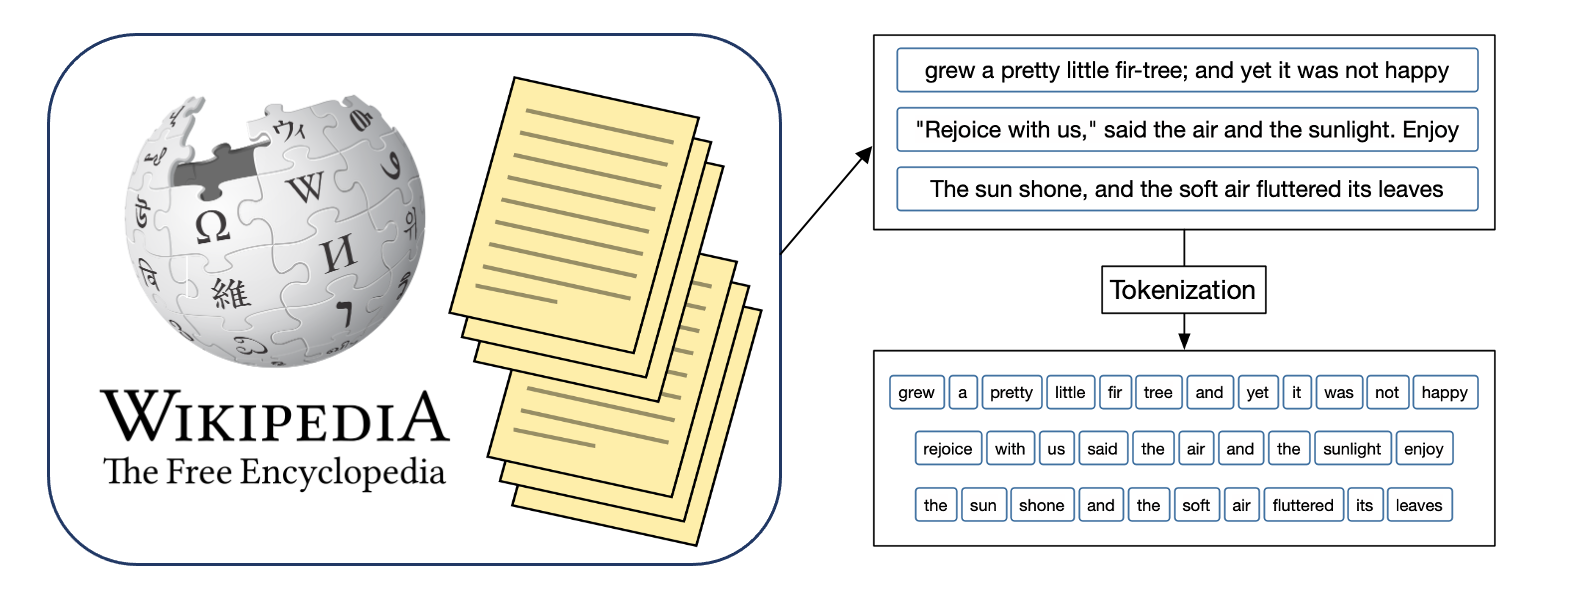

One popular approach is called [**Byte Pair Encoding**](https://github.com/rsennrich/subword-nmt) aka __BPE__. The algorithm starts with a character-level tokenization and then iteratively merges most frequent pairs for N iterations. This results in frequent words being merged into a single token and rare words split into syllables or even characters.

In [ ]:
from nltk.tokenize import WordPunctTokenizer
from subword_nmt.learn_bpe import learn_bpe
from subword_nmt.apply_bpe import BPE

tokenizer = WordPunctTokenizer()

def tokenize(x):
    return ' '.join(tokenizer.tokenize(x.lower()))

# split and tokenize the data
with open('train.en', 'w') as f_src,  open('train.ru', 'w') as f_dst:
    for line in open('data.txt'):
        src_line, dst_line = line.strip().split('\t')
        f_src.write(tokenize(src_line) + '\n')
        f_dst.write(tokenize(dst_line) + '\n')

# build and apply bpe vocs
bpe = {}
for lang in ['en', 'ru']:
    learn_bpe(open('./train.' + lang), open('bpe_rules.' + lang, 'w'), num_symbols=8000)
    bpe[lang] = BPE(open('./bpe_rules.' + lang))

    with open('train.bpe.' + lang, 'w') as f_out:
        for line in open('train.' + lang):
            f_out.write(bpe[lang].process_line(line.strip()) + '\n')

100%|██████████| 8000/8000 [00:04<00:00, 1884.37it/s]


### **1.1. Building vocabularies** (1 point)


We now need to build vocabularies that map strings to token ids and vice versa. We're gonna need these fellas when we feed training data into model or convert output matrices into words.

In [ ]:
!pip3 install "torch>=1.3.0" subword-nmt nltk numpy matplotlib scikit-learn tqdm bokeh transformers peft datasets

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 5.3 MB 581 kB/s eta 0:00:011
     |████████████████████████████████| 7.8 MB 428 kB/s eta 0:00:01
     |████████████████████████████████| 11.1 MB 630 kB/s eta 0:00:01
     |████████████████████████████████| 7.0 MB 282 kB/s eta 0:00:01
     |████████████████████████████████| 12.0 MB 431 kB/s eta 0:00:01     |████████████████████████████    | 10.5 MB 636 kB/s eta 0:00:03
     |████████████████████████████████| 504 kB 434 kB/s eta 0:00:01
     |████████████████████████████████| 511 kB 431 kB/s eta 0:00:01
     |████████████████████████████████| 249 kB 362 kB/s eta 0:00:01
     |████████████████████████████████| 64 kB 837 kB/s eta 0:00:011
     |████████████████████████████████| 113 kB 722 kB/s eta 0:00:01
     |████████████████████████████████| 4.7 MB 430 kB/s eta 0:00:01
     |████████████████████████████████| 2.8 MB 516 kB/s eta 0:00:01
     |█████████████████████████████

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


In [ ]:
data_inp = np.array(open('./train.bpe.ru').read().split('\n'))
data_out = np.array(open('./train.bpe.en').read().split('\n'))

from sklearn.model_selection import train_test_split
train_inp, dev_inp, train_out, dev_out = train_test_split(
    data_inp,
    data_out,
    test_size=3000,
    random_state=42
)
for i in range(3):
    print('inp:', train_inp[i])
    print('out:', train_out[i], end='\n\n')

inp: на территории обустроена бесплатная частная парковка .
out: free private parking is available on site .

inp: кроме того , в 5 минутах ходьбы работают многочисленные бары и рестораны .
out: guests can find many bars and restaurants within a 5 - minute walk .

inp: отель san mi@@ gu@@ el расположен в центре мор@@ ели@@ и , в 750 метрах от главной площади города и кафедрального собора .
out: hotel san miguel is located in central more@@ lia , 750 metres from the city ’ s main square and cathedral .



In [ ]:
from vocab import Vocab

inp_voc = Vocab.from_lines(train_inp)
out_voc = Vocab.from_lines(train_out)

In [ ]:
# Here's how you cast lines into ids and backwards.

batch_lines = sorted(train_inp, key=len)[5:10]
batch_ids = inp_voc.to_matrix(batch_lines)
batch_lines_restored = inp_voc.to_lines(batch_ids)

print("lines")
print(batch_lines)
print("\nwords to ids (0 = bos, 1 = eos):")
print(batch_ids)
print("\nback to words")
print(batch_lines_restored)

lines
[np.str_('гостевой дом r .'), np.str_('до афин — 20 км .'), np.str_('работает боулинг .'), np.str_('оборудован балкон .'), np.str_('подключен wi - fi .')]

words to ids (0 = bos, 1 = eos):
tensor([[   0, 2688, 2943, 1108,   29,    1,    1,    1],
        [   0, 2922, 1834, 8035,   59, 3800,   29,    1],
        [   0, 6030, 2083,   29,    1,    1,    1,    1],
        [   0, 4927, 1870,   29,    1,    1,    1,    1],
        [   0, 5549, 1453,   27,  592,   29,    1,    1]])

back to words
['гостевой дом r .', 'до афин — 20 км .', 'работает боулинг .', 'оборудован балкон .', 'подключен wi - fi .']


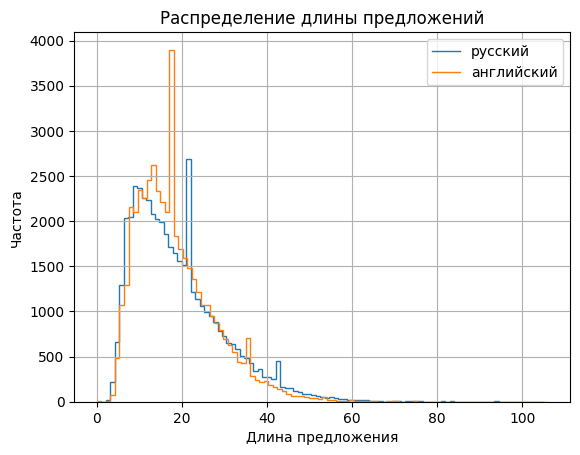

In [ ]:
'''
Draw source and translation length distributions to estimate the scope of the task.
'''
# <YOUR CODE HERE>

train_inp_lens = [len(line.split()) for line in train_inp]
train_out_lens = [len(line.split()) for line in train_out]

counts_inp, bins_inp = np.histogram(train_inp_lens, bins=100)
plt.stairs(counts_inp, bins_inp, label='русский')
counts_out, bins_out = np.histogram(train_out_lens, bins=100)
plt.stairs(counts_out, bins_out, label='английский')

plt.title('Распределение длины предложений')
plt.xlabel('Длина предложения')
plt.ylabel('Частота')
plt.legend()
plt.grid(True)
plt.show()
# <YOUR CODE HERE>

In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


### **1.2. Basic model** (7 points)

#### **1.2.1. Encoder-decoder** (3 points)


The code below contains a template for a **simple encoder-decoder model**: single GRU encoder/decoder, no attention or anything. This model is implemented for you as a reference and a baseline for your homework assignment.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
class BasicModel(nn.Module):
    def __init__(self, inp_voc, out_voc, emb_size=64, hid_size=128):
        """
        A simple encoder-decoder seq2seq model
        """
        super().__init__() # initialize base class to track sub-layers, parameters, etc.

        self.inp_voc, self.out_voc = inp_voc, out_voc
        self.hid_size = hid_size

        self.emb_inp = nn.Embedding(len(inp_voc), emb_size)
        self.emb_out = nn.Embedding(len(out_voc), emb_size)
        self.enc0 = nn.GRU(emb_size, hid_size, batch_first=True)

        self.dec_start = nn.Linear(hid_size, hid_size)
        self.dec0 = nn.GRUCell(emb_size, hid_size)
        self.logits = nn.Linear(hid_size, len(out_voc))


    def forward(self, inp, out):
        """ Apply model in training mode """
        initial_state = self.encode(inp)
        return self.decode(initial_state, out)


    def encode(self, inp, **flags):
        """
        Takes symbolic input sequence, computes initial state
        :param inp: matrix of input tokens [batch, time]
        :returns: initial decoder state tensors, one or many
        """
        inp_emb = self.emb_inp(inp)
        batch_size = inp.shape[0]

        enc_seq, [last_state_but_not_really] = self.enc0(inp_emb)
        # enc_seq: [batch, time, hid_size], last_state: [batch, hid_size]

        # note: last_state is not _actually_ last because of padding, let's find the real last_state
        lengths = (inp != self.inp_voc.eos_ix).to(torch.int64).sum(dim=1).clamp_max(inp.shape[1] - 1)
        last_state = enc_seq[torch.arange(len(enc_seq)), lengths]
        # ^-- shape: [batch_size, hid_size]

        dec_start = self.dec_start(last_state)
        return [dec_start]

    def decode_step(self, prev_state, prev_tokens, **flags):
        """
        Takes previous decoder state and tokens, returns new state and logits for next tokens
        :param prev_state: a list of previous decoder state tensors, same as returned by encode(...)
        :param prev_tokens: previous output tokens, an int vector of [batch_size]
        :return: a list of next decoder state tensors, a tensor of logits [batch, len(out_voc)]
        """
        prev_gru0_state = prev_state[0]

        # <YOUR CODE HERE>
        out_emb =  self.emb_out(prev_tokens)
        new_dec_state = self.dec0(out_emb, prev_gru0_state)
        output_logits = self.logits(new_dec_state)
        # <YOUR CODE HERE>
        # new_dec_state = [new_dec_state]
        return [new_dec_state], output_logits

    def decode(self, initial_state, out_tokens, **flags):
        """ Iterate over reference tokens (out_tokens) with decode_step """
        batch_size = out_tokens.shape[0]
        state = initial_state

        # initial logits: always predict BOS
        onehot_bos = F.one_hot(torch.full([batch_size], self.out_voc.bos_ix, dtype=torch.int64),
                               num_classes=len(self.out_voc)).to(device=out_tokens.device)
        first_logits = torch.log(onehot_bos.to(torch.float32) + 1e-9)

        logits_sequence = [first_logits]
        for i in range(out_tokens.shape[1] - 1):
            state, logits = self.decode_step(state, out_tokens[:, i])
            logits_sequence.append(logits)
        return torch.stack(logits_sequence, dim=1)

    def decode_inference(self, initial_state, max_len=100, **flags):
        """ Generate translations from model (greedy version) """
        batch_size, device = len(initial_state[0]), initial_state[0].device
        state = initial_state
        outputs = [torch.full([batch_size], self.out_voc.bos_ix, dtype=torch.int64,
                              device=device)]
        all_states = [initial_state]

        for i in range(max_len):
            state, logits = self.decode_step(state, outputs[-1])
            outputs.append(logits.argmax(dim=-1))
            all_states.append(state)

        return torch.stack(outputs, dim=1), all_states

    def translate_lines(self, inp_lines, **kwargs):
        inp = self.inp_voc.to_matrix(inp_lines).to(device)
        initial_state = self.encode(inp)
        out_ids, states = self.decode_inference(initial_state, **kwargs)
        return self.out_voc.to_lines(out_ids.cpu().numpy()), states

In [ ]:
# debugging area
model = BasicModel(inp_voc, out_voc).to(device)

dummy_inp_tokens = inp_voc.to_matrix(sorted(train_inp, key=len)[5:10]).to(device)
dummy_out_tokens = out_voc.to_matrix(sorted(train_out, key=len)[5:10]).to(device)

h0 = model.encode(dummy_inp_tokens)
h1, logits1 = model.decode_step(h0, torch.arange(len(dummy_inp_tokens), device=device))

assert isinstance(h1, list) and len(h1) == len(h0)
assert h1[0].shape == h0[0].shape and not torch.allclose(h1[0], h0[0])
assert logits1.shape == (len(dummy_inp_tokens), len(out_voc))

logits_seq = model.decode(h0, dummy_out_tokens)
assert logits_seq.shape == (dummy_out_tokens.shape[0], dummy_out_tokens.shape[1], len(out_voc))

# full forward
logits_seq2 = model(dummy_inp_tokens, dummy_out_tokens)
assert logits_seq2.shape == logits_seq.shape

In [ ]:
dummy_translations, dummy_states = model.translate_lines(train_inp[:3], max_len=25)

print("Translations without training:\n")
for orig, trans in zip(train_inp[:3], dummy_translations):
    print("-" * 40)
    print(f"Original: {orig}")
    print(f"Translation: {trans}")

Translations without training:

----------------------------------------
Original: на территории обустроена бесплатная частная парковка .
Translation: j acu@@ gre@@ palazzo til folk miram@@ mam@@ smeralda ws hot@@ harmo@@ requests riverfront aj@@ zhong@@ earth solar@@ solar@@ lodge raj@@ til use@@ sund@@ border
----------------------------------------
Original: кроме того , в 5 минутах ходьбы работают многочисленные бары и рестораны .
Translation: j acu@@ gre@@ palazzo til folk miram@@ mam@@ smeralda ws hot@@ harmo@@ requests riverfront aj@@ zhong@@ earth solar@@ solar@@ lodge raj@@ til use@@ sund@@ border
----------------------------------------
Original: отель san mi@@ gu@@ el расположен в центре мор@@ ели@@ и , в 750 метрах от главной площади города и кафедрального собора .
Translation: open dy uns storey zi@@ siana zo@@ lawn ragusa sult@@ sult@@ siana ü@@ piazza ů@@ bast@@ aland rom@@ lat@@ cast@@ thani sto 17@@ case ceram@@


#### **1.2.2. Training loss** (2 points)

Our training objective is almost the same as it was for neural language models:
$$ L = {\frac1{|D|}} \sum_{X, Y \in D} \sum_{y_t \in Y} - \log p(y_t \mid y_1, \dots, y_{t-1}, X, \theta) $$

where $|D|$ is the __total length of all sequences__, including BOS and first EOS, but excluding PAD.

In [ ]:
def compute_loss(model, inp, out, **flags):
    """
    Compute loss (float32 scalar) as in the formula above
    :param inp: input tokens matrix, int32[batch, time]
    :param out: reference tokens matrix, int32[batch, time]

    In order to pass the tests, your function should
    * include loss at first EOS but not the subsequent ones
    * divide sum of losses by a sum of input lengths (use voc.compute_mask)
    """
    mask = model.out_voc.compute_mask(out) # [batch_size, out_len]
    targets_1hot = F.one_hot(out, len(model.out_voc)).to(torch.float32)

    # outputs of the model, [batch_size, out_len, num_tokens]
    # <YOUR CODE HERE>
    outputs = model.forward(inp, out)
    # <YOUR CODE HERE>

    # log-probabilities of all tokens at all steps, [batch_size, out_len, num_tokens]
    # <YOUR CODE HERE>
    exp = torch.exp(outputs)
    sum_exp = exp.sum(dim=-1, keepdim=True)
    logprobs_seq = outputs - torch.log(sum_exp)
    # <YOUR CODE HERE>

    # log-probabilities of correct outputs, [batch_size, out_len]
    logp_out = (logprobs_seq * targets_1hot).sum(dim=-1)
    # ^-- this will select the probability of the actual next token.
    # Note: you can compute loss more efficiently using using F.cross_entropy

    # average cross-entropy over tokens where mask == True
    # <YOUR CODE HERE>
    loss = -logp_out * mask.to(torch.float32)
    average_loss = loss.sum()/mask.sum()
    return average_loss  # average loss, scalar
    # <YOUR CODE HERE>

In [ ]:
dummy_inp_tokens

tensor([[   0, 2688, 2943, 1108,   29,    1,    1,    1],
        [   0, 2922, 1834, 8035,   59, 3800,   29,    1],
        [   0, 6030, 2083,   29,    1,    1,    1,    1],
        [   0, 4927, 1870,   29,    1,    1,    1,    1],
        [   0, 5549, 1453,   27,  592,   29,    1,    1]])

In [ ]:
out = model.forward(dummy_inp_tokens, dummy_out_tokens)
out[-1, :, 10:]

tensor([[-2.0723e+01, -2.0723e+01, -2.0723e+01,  ..., -2.0723e+01,
         -2.0723e+01, -2.0723e+01],
        [ 1.1782e-01,  1.9331e-01,  4.4065e-02,  ...,  2.4324e-02,
         -1.0621e-01, -8.7482e-02],
        [ 1.4700e-01,  2.3944e-01, -4.6367e-02,  ..., -2.1087e-01,
         -2.6026e-01,  6.4889e-02],
        ...,
        [ 3.2860e-01,  8.4389e-02,  9.1855e-02,  ..., -3.3992e-01,
         -1.8767e-01,  1.1902e-01],
        [ 1.8049e-01,  8.3757e-02,  3.5941e-03,  ..., -1.1612e-01,
         -1.0477e-01,  1.2962e-01],
        [-2.0415e-02,  3.4316e-02,  1.4037e-01,  ..., -1.6911e-01,
         -2.1180e-01,  2.1177e-01]], grad_fn=<SliceBackward0>)

In [ ]:
dummy_loss = compute_loss(model, dummy_inp_tokens, dummy_out_tokens)
print("Loss:", dummy_loss)
assert np.allclose(dummy_loss.item(), 7.5, rtol=0.1, atol=0.1), "We're sorry for your loss"

# test autograd
dummy_loss.backward()
for name, param in model.named_parameters():
    assert param.grad is not None and abs(param.grad.max()) != 0, f"Param {name} received no gradients"

Loss: tensor(7.5740, grad_fn=<DivBackward0>)


#### **1.2.3. Evaluation: BLEU**


Machine translation is commonly evaluated with [BLEU](https://en.wikipedia.org/wiki/BLEU) score. This metric simply computes which fraction of predicted n-grams is actually present in the reference translation. It does so for n=1,2,3 and 4 and computes the geometric average with penalty if translation is shorter than reference.

While BLEU [has many drawbacks](https://www.cis.upenn.edu/~ccb/publications/re-evaluating-the-role-of-bleu-in-mt-research.pdf), it still remains the most commonly used metric and one of the simplest to compute.

In [ ]:
from nltk.translate.bleu_score import corpus_bleu
def compute_bleu(model, inp_lines, out_lines, bpe_sep='@@ ', **flags):
    """
    Estimates corpora-level BLEU score of model's translations given inp and reference out
    Note: if you're serious about reporting your results, use https://pypi.org/project/sacrebleu
    """
    with torch.no_grad():
        translations, _ = model.translate_lines(inp_lines, **flags)
        translations = [line.replace(bpe_sep, '') for line in translations]
        actual = [line.replace(bpe_sep, '') for line in out_lines]
        return corpus_bleu(
            [[ref.split()] for ref in actual],
            [trans.split() for trans in translations],
            smoothing_function=lambda precisions, **kw: [p + 1.0 / p.denominator for p in precisions]
            ) * 100

In [ ]:
compute_bleu(model, dev_inp, dev_out)

0.002177364665907333

#### **1.2.4. Training loop** (2 points)

Training encoder-decoder models isn't that different from any other models: sample batches, compute loss, backprop and update

In [ ]:
from IPython.display import clear_output
from tqdm import tqdm, trange

metrics = {'train_loss': [], 'dev_bleu': [] }

# define all necessary variables here
# <YOUR CODE HERE>
batch_size=64
lr=0.001
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
# <YOUR CODE HERE>

In [ ]:
for _ in trange(25000):
    step = len(metrics['train_loss']) + 1
    batch_ix = np.random.randint(len(train_inp), size=batch_size)
    batch_inp = inp_voc.to_matrix(train_inp[batch_ix]).to(device)
    batch_out = out_voc.to_matrix(train_out[batch_ix]).to(device)

    # training step using batch_inp and batch_out
    # <YOUR CODE>
    optimizer.zero_grad()
    loss_t = compute_loss(model, batch_inp, batch_out)
    loss_t.backward()
    optimizer.step()
    # <YOUR CODE>

    metrics['train_loss'].append((step, loss_t.item()))

    if step % 100 == 0:
        metrics['dev_bleu'].append((step, compute_bleu(model, dev_inp, dev_out)))

        clear_output(True)
        plt.figure(figsize=(12,4))
        for i, (name, history) in enumerate(sorted(metrics.items())):
            plt.subplot(1, len(metrics), i + 1)
            plt.title(name)
            plt.plot(*zip(*history))
            plt.grid()
        plt.show()
        print("Mean loss=%.3f" % np.mean(metrics['train_loss'][-10:], axis=0)[1], flush=True)

# Note: it's okay if bleu oscillates up and down as long as it gets better on average over long term (e.g. 5k batches)

In [ ]:
model.load_state_dict(torch.load('hw 2 model weights.pt', map_location=device))
model.to(device)
model.eval()

BasicModel(
  (emb_inp): Embedding(8048, 64)
  (emb_out): Embedding(7801, 64)
  (enc0): GRU(64, 128, batch_first=True)
  (dec_start): Linear(in_features=128, out_features=128, bias=True)
  (dec0): GRUCell(64, 128)
  (logits): Linear(in_features=128, out_features=7801, bias=True)
)

In [ ]:
assert np.mean(metrics['dev_bleu'][-10:], axis=0)[1] > 15, "We kind of need a higher bleu BLEU from you. Kind of right now."

In [ ]:
for inp_line, trans_line in zip(dev_inp[::500], model.translate_lines(dev_inp[::500])[0]):
    print(inp_line)
    print(trans_line)
    print()

в распоряжении гостей общая кухня и общая гостиная .
there is a shared kitchen and communal kitchen .

кроме того , предоставляется прокат велосипедов , услуги трансфера и бесплатная парковка .
it offers bike rental , an outdoor pool and free shuttle service .

расстояние до города ки@@ сси@@ м@@ ми составляет 26 км .
the unit is 26 km from the property .

апартаменты в пент@@ хаусе с общим открытым бассейном , садом , кондиционером и террасой для загара расположены в 5 минутах ходьбы от пляжа на курорте ка@@ бо - рой .
located a 5 - minute drive from the beach , margar@@ ita beach offers a sauna and a garden .

апартаменты mo@@ s@@ co@@ w point - loft red square находятся в москве , в 200 метрах от большого театра .
featuring free wifi , air - conditioned rooms are within a 32 - minute walk from the centre .

в вашем распоряжении собственная ванная комната с душем и полотенцами .
featuring a shower , private bathroom also comes with towels .



### **1.3. Your Attention Required** (13 points)



In this section we want you to improve over the basic model by implementing a simple attention mechanism.

This is gonna be a two-parter: building the __attention layer__ and using it for an __attentive seq2seq model__.

#### **1.3.1. Attention layer** (3 points)


Here you will have to implement a layer that computes a simple additive attention:

Given encoder sequence $ h^e_0, h^e_1, h^e_2, ..., h^e_T$ and a single decoder state $h^d$,

* Compute logits with a 2-layer neural network
$$a_t = \text{linear}_{out}(\tanh(\text{linear}_{e}(h^e_t) + \text{linear}_{d}(h_d)))$$
* Get probabilities from logits,
$$ p_t = {{e ^ {a_t}} \over { \sum_\tau e^{a_\tau} }} $$

* Add up encoder states with probabilities to get __attention response__
$$ attn = \sum_t p_t \cdot h^e_t $$

You can learn more about attention layers in the lecture slides or [from this post](https://distill.pub/2016/augmented-rnns/).

In [ ]:
class AttentionLayer(nn.Module):
    def __init__(self, name, enc_size, dec_size, hid_size, activ=torch.tanh):
        """ A layer that computes additive attention response and weights """
        super().__init__()
        self.name = name
        self.enc_size = enc_size   # num units in encoder state
        self.dec_size = dec_size   # num units in decoder state
        self.hid_size = hid_size   # attention layer hidden units
        self.activ = activ         # attention layer hidden nonlinearity

        # create trainable paramteres like this:
        # self.<PARAMETER_NAME> = nn.Parameter(<INITIAL_VALUES>, requires_grad=True)
        # <YOUR CODE HERE>
        self.linear_enc = nn.Linear(enc_size, hid_size)
        self.linear_dec = nn.Linear(dec_size, hid_size)
        self.linear_out = nn.Linear(hid_size, 1)
        self.softmax = nn.Softmax(dim=1)
        # <YOUR CODE HERE>


    def forward(self, enc, dec, inp_mask):
        """
        Computes attention response and weights
        :param enc: encoder activation sequence, float32[batch_size, ninp, enc_size]
        :param dec: single decoder state used as "query", float32[batch_size, dec_size]
        :param inp_mask: mask on enc activatons (0 after first eos), float32 [batch_size, ninp]
        :returns: attn[batch_size, enc_size], probs[batch_size, ninp]
            - attn - attention response vector (weighted sum of enc)
            - probs - attention weights after softmax
        """

        # Compute logits float[batch_size, ninp, 1]}
        # <YOUR CODE HERE>
        logits = self.linear_out(self.activ(
            self.linear_enc(enc) + self.linear_dec(dec).unsqueeze(1)))
        # <YOUR CODE HERE>

        # Apply mask - if mask is 0, logits should be -inf or -1e9
        # You may need torch.where
        # <YOUR CODE HERE>
        logits = torch.where(inp_mask.unsqueeze(2).bool(), logits, torch.tensor(-1e9, device=logits.device))
        # <YOUR CODE HERE>

        # Compute attention probabilities (softmax)
        # <YOUR CODE HERE>
        probs = self.softmax(logits)
        # <YOUR CODE HERE>

        # Compute attention response using enc and probs
        # <YOUR CODE HERE>
        attn = torch.sum(probs * enc, dim=1)
        # <YOUR CODE HERE>

        return attn, probs

#### **1.3.2. Seq2seq model with attention** (3 points)


You can now use the attention layer to build a network. The simplest way to implement attention is to use it in decoder phase:

<br>

![img](https://i.imgur.com/6fKHlHb.png)

<br>

On every step, use __previous__ decoder state to obtain attention response. Then feed concat this response to the inputs of next attention layer.

The key implementation detail here is __model state__. Put simply, you can add any tensor into the list of `encode` outputs. You will then have access to them at each `decode` step. This may include:
* Last RNN hidden states (as in basic model)
* The whole sequence of encoder outputs (to attend to) and mask
* Attention probabilities (to visualize)

_There are, of course, alternative ways to wire attention into your network and different kinds of attention. Take a look at [this](https://arxiv.org/abs/1609.08144), [this](https://arxiv.org/abs/1706.03762) and [this](https://arxiv.org/abs/1808.03867) for ideas. And for image captioning/im2latex there's [visual attention](https://arxiv.org/abs/1502.03044)_

In [ ]:
class AttentiveModel(BasicModel):
    def __init__(self, name, inp_voc, out_voc,
                 emb_size=64, hid_size=128, attn_size=128):
        """ Translation model that uses attention. See instructions above. """
        # nn.Module.__init__(self)  # initialize base class to track sub-layers, trainable variables, etc.
        super().__init__(inp_voc, out_voc, emb_size, hid_size)
        #self.inp_voc, self.out_voc = inp_voc, out_voc
        #self.hid_size = hid_size

        # initialize layers
        # <YOUR CODE HERE>
        self.dec0 = nn.GRUCell(emb_size + hid_size, hid_size)
        self.attn = AttentionLayer('attn', hid_size, hid_size, attn_size)
        # <YOUR CODE HERE>


    def encode(self, inp, **flags):
        """
        Takes symbolic input sequence, computes initial state
        :param inp: matrix of input tokens [batch, time]
        :return: a list of initial decoder state tensors
        """

        # encode input sequence, create initial decoder states
        # <YOUR CODE HERE>
        inp_emb = self.emb_inp(inp)  # [batch, time, emb_size]
        enc_seq, [last_state_but_not_really] = self.enc0(inp_emb) # [batch_size, time, hid_size] , [1, batch_size, hid_size]
        # note: last_state is not _actually_ last because of padding, let's find the real last_state
        lengths = (inp != self.inp_voc.eos_ix).to(torch.int64).sum(dim=1).clamp_max(inp.shape[1] - 1)
        last_state = enc_seq[torch.arange(len(enc_seq)), lengths]
        dec_start = self.dec_start(last_state.squeeze(0))
        # <YOUR CODE HERE>

        # apply attention layer from initial decoder hidden state
        # <YOUR CODE HERE>
        inp_mask = (inp != self.inp_voc.eos_ix).to(torch.float32)
        dec_start_attn, dec_probs = self.attn(enc_seq, dec_start, inp_mask)
        # <YOUR CODE HERE>

        # Build first state: include
        # * initial states for decoder recurrent layers
        # * encoder sequence and encoder attn mask (for attention)
        # * make sure that last state item is attention probabilities tensor

        # <YOUR CODE HERE>
        first_state = [dec_start, enc_seq, inp_mask, dec_probs] # [batch_size, hid_size] [batch_size, time, hid_size] [batch_size, time]
        # <YOUR CODE HERE>
        return first_state


    def decode_step(self, prev_state, prev_tokens, **flags):
        """
        Takes previous decoder state and tokens, returns new state and logits for next tokens
        :param prev_state: a list of previous decoder state tensors
        :param prev_tokens: previous output tokens, an int vector of [batch_size]
        :return: a list of next decoder state tensors, a tensor of logits [batch, n_tokens]
        """

        # <YOUR CODE HERE>
        dec_start, enc_seq, inp_mask, dec_attn = prev_state
        atnn, probs = self.attn(enc_seq, dec_start, inp_mask)
        prev_emb = self.emb_out(prev_tokens)

        new_dec_state = self.dec0(torch.cat([prev_emb, atnn], dim=1))
        output_logits = self.logits(new_dec_state)
        new_state = [new_dec_state, enc_seq, inp_mask, probs]
        # <YOUR CODE HERE>

        return new_state, output_logits

#### **1.3.3. Training attentive model** (4 points)

Please reuse the infrastructure you've built for the basic model. I hope you didn't hard-code anything :)

In [ ]:
model = AttentiveModel('attn',inp_voc, out_voc).to(device)

In [ ]:
# create AttentiveModel and training utilities
# <YOUR CODE HERE>
from IPython.display import clear_output
from tqdm import tqdm, trange

metrics = {'train_loss': [], 'dev_bleu': [] }

# define all necessary variables here
# <YOUR CODE HERE>
batch_size=32
lr=0.001
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
# <YOUR CODE HERE>
# <YOUR CODE HERE>

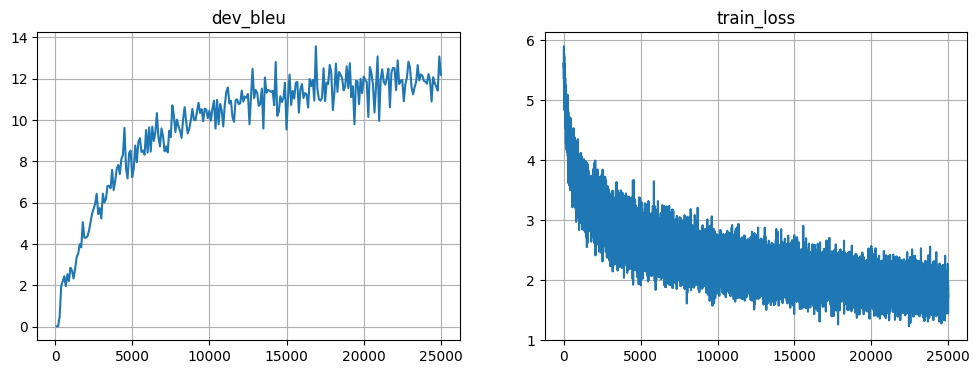

Mean loss=1.760


100%|██████████| 25000/25000 [9:41:13<00:00,  1.39s/it]


In [ ]:
# training loop
# <YOUR CODE HERE>

for _ in trange(25000):
    step = len(metrics['train_loss']) + 1
    batch_ix = np.random.randint(len(train_inp), size=batch_size)
    batch_inp = inp_voc.to_matrix(train_inp[batch_ix]).to(device)
    batch_out = out_voc.to_matrix(train_out[batch_ix]).to(device)

    # training step using batch_inp and batch_out
    # <YOUR CODE>
    optimizer.zero_grad()
    loss_t = compute_loss(model, batch_inp, batch_out)
    loss_t.backward()
    optimizer.step()
    # <YOUR CODE>

    metrics['train_loss'].append((step, loss_t.item()))

    if step % 100 == 0:
        metrics['dev_bleu'].append((step, compute_bleu(model, dev_inp, dev_out)))

        clear_output(True)
        plt.figure(figsize=(12,4))
        for i, (name, history) in enumerate(sorted(metrics.items())):
            plt.subplot(1, len(metrics), i + 1)
            plt.title(name)
            plt.plot(*zip(*history))
            plt.grid()
        plt.show()
        print("Mean loss=%.3f" % np.mean(metrics['train_loss'][-10:], axis=0)[1], flush=True)

# Note: it's okay if bleu oscillates up and down as long as it gets better on average over long term (e.g. 5k batches)
# <YOUR CODE HERE>

In [ ]:
# save_path = 'model_weights_attn.pt'
# torch.save(model.state_dict(), save_path)

In [ ]:
assert np.mean(metrics['dev_bleu'][-10:], axis=0)[1] > 24, "What if I told you... You can get higher!"

AssertionError: What if I told you... You can get higher!

In [ ]:
# measure final BLEU and show translation examples
# <YOUR CODE HERE>

for inp_line, trans_line in zip(dev_inp[::500], model.translate_lines(dev_inp[::500])[0]):
    print(inp_line)
    print(trans_line)
    print()
# <YOUR CODE HERE>

в распоряжении гостей общая кухня и общая гостиная .
there is a shared kitchen and a shared living room .

кроме того , предоставляется прокат велосипедов , услуги трансфера и бесплатная парковка .
the property also offers bike rentals and free parking .

расстояние до города ки@@ сси@@ м@@ ми составляет 26 км .
the property .

апартаменты в пент@@ хаусе с общим открытым бассейном , садом , кондиционером и террасой для загара расположены в 5 минутах ходьбы от пляжа на курорте ка@@ бо - рой .
featuring a shared garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden , a garden

апартаменты mo@@ s@@ co@@ w point - loft red square находятся в москве , в 200 метрах от большого театра .
the trevi fountai

#### **1.3.4. Visualizing model attention** (2 points)


After training the attentive translation model, you can check it's sanity by visualizing its attention weights.

We provided you with a function that draws attention maps using [`Bokeh`](https://bokeh.pydata.org/en/latest/index.html). Once you managed to produce something better than random noise, please save at least 3 attention maps and __submit them to anytask__ alongside this notebook to get the max grade. Saving bokeh figures as __cell outputs is not enough!__ (TAs can't see saved bokeh figures in anytask). You can save bokeh images as screenshots or using this button:

![bokeh_panel](https://github.com/yandexdataschool/nlp_course/raw/2019/resources/bokeh_panel.png)

__Note:__ you're not locked into using bokeh. If you prefer a different visualization method, feel free to use that instead of bokeh.

In [ ]:
import bokeh.plotting as pl
import bokeh.models as bm
from bokeh.io import output_notebook, show
from bokeh.layouts import row

output_notebook()

def draw_attention(inp_line, translation, probs):
    """ An intentionally ambiguous function to visualize attention weights """
    inp_tokens = inp_voc.tokenize(inp_line)
    trans_tokens = out_voc.tokenize(translation)
    probs = probs[:len(trans_tokens), :len(inp_tokens)]

    fig = pl.figure(x_range=(0, len(inp_tokens)), y_range=(0, len(trans_tokens)),
                    x_axis_type=None, y_axis_type=None, tools=[],
                    width=400, height=400)
    fig.image([probs[::-1]], 0, 0, len(inp_tokens), len(trans_tokens))

    fig.add_layout(bm.LinearAxis(axis_label='source tokens'), 'above')
    fig.xaxis.ticker = np.arange(len(inp_tokens)) + 0.5
    fig.xaxis.major_label_overrides = dict(zip(np.arange(len(inp_tokens)) + 0.5, inp_tokens))
    fig.xaxis.major_label_orientation = 45

    fig.add_layout(bm.LinearAxis(axis_label='translation tokens'), 'left')
    fig.yaxis.ticker = np.arange(len(trans_tokens)) + 0.5
    fig.yaxis.major_label_overrides = dict(zip(np.arange(len(trans_tokens)) + 0.5, trans_tokens[::-1]))

    return fig

Loading BokehJS ...

In [ ]:
inp = dev_inp[::500]
trans, states = attentive_model.translate_lines(inp)

# select attention probs from model state (you may need to change this for your custom model)
# attention_probs below must have shape [batch_size, translation_length, input_length], extracted from states

# <YOUR CODE HERE>

# <YOUR CODE HERE>

In [ ]:
figures = []
for i in range(4):
    fig = draw_attention(inp[i], trans[i], attention_probs[i])
    figures.append(fig)

show(row(figures))

# Does it look fine already?

__Note 1:__ If the attention maps are not iterpretable, try starting encoder from zeros (instead of dec_start), forcing model to use attention.

#### **1.3.5. Conclusions** (1 point)


Please write here what conclusions you can draw from the **appearance of the attention matrices**. Describe your observations as a list and briefly - one point one idea. If you can, support your observations with a relevant paper.

<br>

*  `<YOUR CONCLUSIONS>` [1]

<br>

[1] Vaswani, A. et. al. [Attention Is All You Need](https://arxiv.org/abs/1706.03762). NeurIPS 2017.

## **Task 2.** Parameter Efficient Fine-Tuning (19 points)

### **2.1. Loading model**

In [2]:
%pip install --quiet sentencepiece==0.1.99 optimum==1.13.2 peft==0.5.0
%pip install accelerate==1.11.0 huggingface-hub==0.36.0 tokenizers==0.22.1 transformers==4.57.1
%pip install bitsandbytes

  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
%pip install accelerate==1.11.0

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import transformers
from tqdm.auto import tqdm, trange

assert torch.cuda.is_available(), "you need cuda for this part"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [5]:
model_name = 'Enoch/llama-7b-hf'

# loading Llama tokenizer ...
tokenizer = transformers.LlamaTokenizer.from_pretrained(model_name, device_map=device)
tokenizer.pad_token_id = tokenizer.eos_token_id

# ... and the model itself
model = transformers.AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map='auto',
    low_cpu_mem_usage=True,
    offload_state_dict=True,
    load_in_4bit=True,
    torch_dtype=torch.float32,  # weights are 4-bit; layernorms and activations are fp32
)

for param in model.parameters():
    param.requires_grad=False

# only store a small subset of activations, re-compute the rest.
model.gradient_checkpointing_enable()

# override an implementation quirk in gradient checkpoints that disables backprop unless inputs require grad
model.enable_input_require_grads()

# more on gradient checkpointing: https://pytorch.org/docs/stable/checkpoint.html https://arxiv.org/abs/1604.06174

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/218 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.llama.tokenization_llama.LlamaTokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565 - if you loaded a llama tokenizer from a GGUF file you can ignore this message


config.json:   0%|          | 0.00/511 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!
The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.


pytorch_model.bin.index.json: 0.00B [00:00, ?B/s]

Fetching 33 files:   0%|          | 0/33 [00:00<?, ?it/s]

pytorch_model-00004-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00003-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00006-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00008-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00002-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00007-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00001-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00005-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

pytorch_model-00009-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00010-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00011-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00012-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00013-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00014-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00015-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00016-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00017-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00018-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00019-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00020-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00021-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00022-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00023-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00024-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00025-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00026-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00028-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00027-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00029-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00030-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00031-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00032-of-00033.bin:   0%|          | 0.00/405M [00:00<?, ?B/s]

pytorch_model-00033-of-00033.bin:   0%|          | 0.00/524M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/33 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/151 [00:00<?, ?B/s]

### **2.2. Prompt tuning: The story of a fox** (2 points)

In [ ]:
prompt = 'A quick brown fox'
batch = tokenizer(prompt, return_tensors='pt', return_token_type_ids=False).to(device)

for i in range(10):
    next_token = model(**batch).logits[0, -1].argmax(-1).reshape(1, 1)
    batch['input_ids'] = torch.cat([batch['input_ids'], next_token], dim=-1)
    batch['attention_mask'] = torch.cat([batch['attention_mask'], torch.ones_like(next_token)], dim=-1)

print("\n\033[1mPredicted tokens:\033[0m", tokenizer.decode(batch['input_ids'][0].cpu().numpy().tolist()).replace('\n', '\\n'))


Predicted tokens: <s>A quick brown fox jumps over the lazy dog.\nA quick


What a blatant lie! This particular fox assures you that it didn't in fact jump over the lazy dog. No, sir! The fox was just minding its own business. __Your task is to train the model to say truth: no dog was jumped over today.__

<br>

![img](https://i.imgur.com/Ux3qQAu.png)

In [ ]:
the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"
batch = tokenizer(the_truth, return_tensors='pt', return_token_type_ids=False).to(device)
outputs = model(**batch)

next_word_logits = outputs.logits[:, :-1]
true_next_tokens = batch['input_ids'][:, 1:]
loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))

print("Loss:", loss)

Loss: tensor(3.0729, device='cuda:0', grad_fn=<NllLossBackward0>)


Except, we can't train the entire model $-$ that would be 28GB gradients in `float32`. Instead, let's run [prompt tuning](https://arxiv.org/abs/2104.08691).

<img src="https://i.imgur.com/VwNNKnb.png" alt="img" width="800"/>

In [ ]:
class WordEmbeddingsWithLearnedPrompts(nn.Module):
    """
    To perform prompt tuning, you will need to replace model's original word embeddings with a layer - THIS layer
     - that inserts trainable prompts instead of the first N token embeddings. """

    def __init__(self, word_embeddings: nn.Embedding, num_prompts: int):
        super().__init__()
        self.original_word_embeddings = word_embeddings
        self.num_prompts = num_prompts
        self.learnable_prompts = nn.Parameter(
            torch.randn(1, num_prompts, word_embeddings.embedding_dim), requires_grad=True)

    def forward(self, input_ids: torch.LongTensor):
        # input_ids shape: [batch_size, seq length]
        assert input_ids.dtype == torch.int64
        assert input_ids.shape[1] > self.num_prompts
        assert torch.all(input_ids[:, :self.num_prompts] == tokenizer.pad_token_id).item(), "don't forget to prepend several BOS tokens to input_ids"

        # Your task: embed input_ids, but replace the first :num_prompts: tokens with self.learnable_prompts
        # This is because we will prepend :num_prompts: padding tokens at the beginning

        # After you are done, you must produce a word embedding vector for each token in input_ids,
        # except that the first :num_prompts: vectors should equal learnable_prompts;
        # any additional vectors after first :num_prompts: ones should be embedded as usual
        # Note: since you're dealing with trainable params, please torch.cat instead of item assignment

        # <YOUR CODE HERE>
        inp_emb = self.original_word_embeddings(input_ids[:, self.num_prompts:])
        batch_size = input_ids.shape[0]
        prompts = self.learnable_prompts.expand(batch_size, -1, -1)
        outputs = torch.cat([prompts, inp_emb], dim=1)
        # <YOUR CODE HERE>

        return outputs

In [ ]:
num_prompts = 16
test_emb_layer = WordEmbeddingsWithLearnedPrompts(model.model.embed_tokens, num_prompts=num_prompts).to(device)
test_input_ids = tokenizer("a cat say on a may", return_tensors='pt')['input_ids'].to(device)

space_for_prompts = torch.full(
    [len(test_input_ids), num_prompts],
    fill_value=tokenizer.pad_token_id,
    dtype=torch.int64,
    device=device
)
test_inputs_with_prompts = torch.cat([space_for_prompts, test_input_ids], dim=1)

with torch.amp.autocast(device_type='cuda'):
  test_prompt_embeddings = test_emb_layer(test_inputs_with_prompts)

assert test_prompt_embeddings.shape[:2] == test_inputs_with_prompts.shape
assert test_prompt_embeddings.shape[-1] == model.config.hidden_size
assert torch.allclose(test_prompt_embeddings[:, :num_prompts], test_emb_layer.learnable_prompts.float())
assert torch.allclose(test_prompt_embeddings[:, num_prompts:], model.model.embed_tokens(test_input_ids).float())

print("Looks legit!")

Looks legit!


__Now that it works,__ let's inject learnable prompts into the main model and teach it about foxes.

In [ ]:
import matplotlib.pyplot as plt


In [ ]:
assert isinstance(model.model.embed_tokens, nn.Embedding), "you have already replaced the embedding layer. If the replacement is broken, please reload the model"

model.model.embed_tokens = WordEmbeddingsWithLearnedPrompts(model.model.embed_tokens, num_prompts=num_prompts).to(device)

opt = torch.optim.Adam([model.model.embed_tokens.learnable_prompts], lr=0.01)

Loss: tensor(5.8185, device='cuda:0', grad_fn=<NllLossBackward0>)


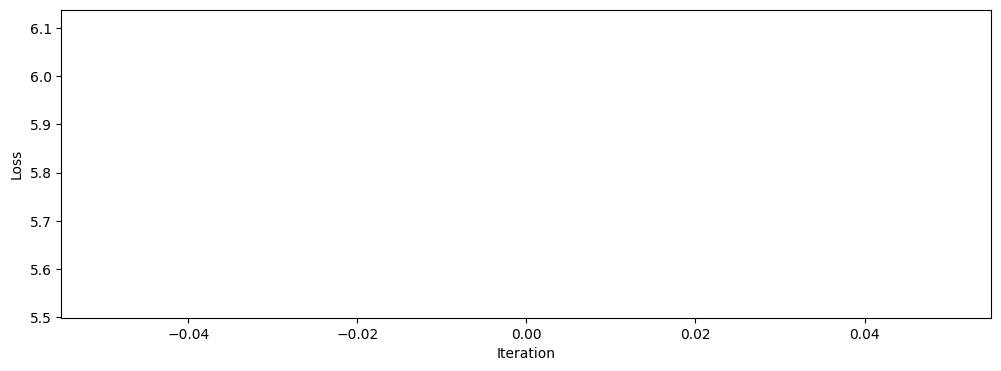

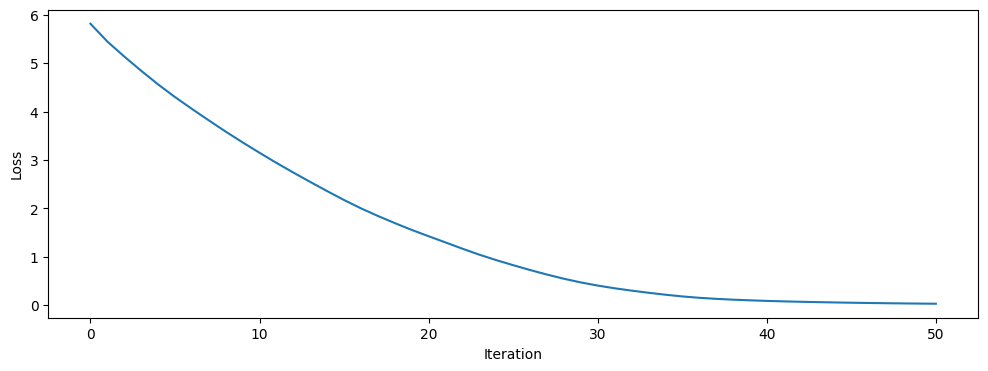

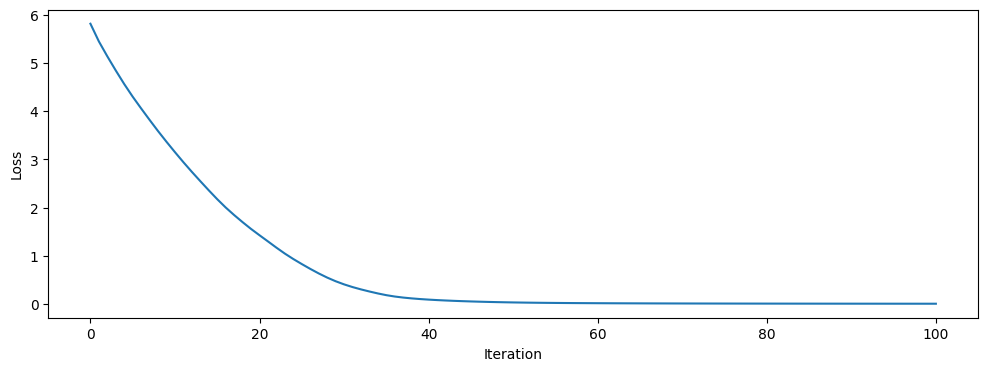

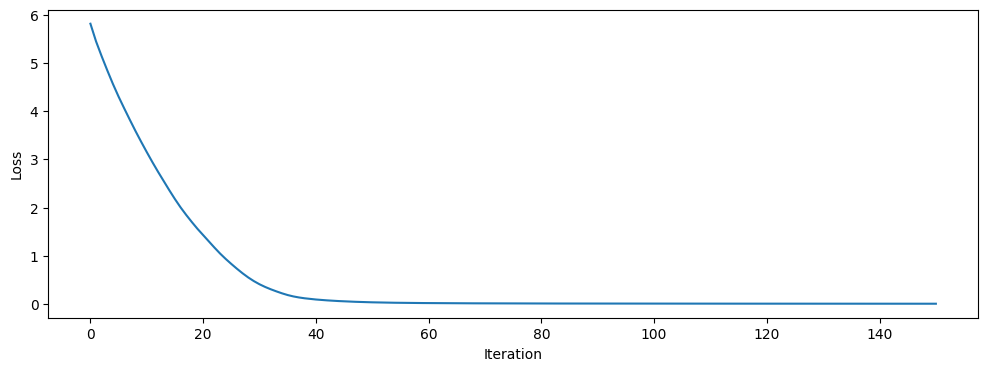

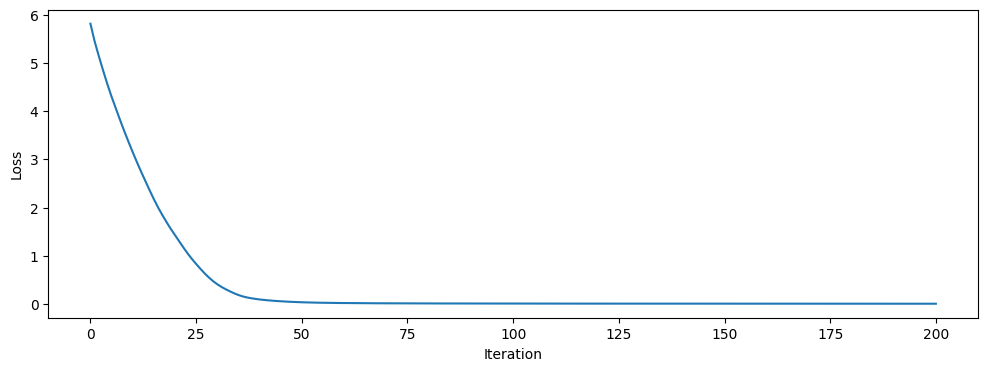

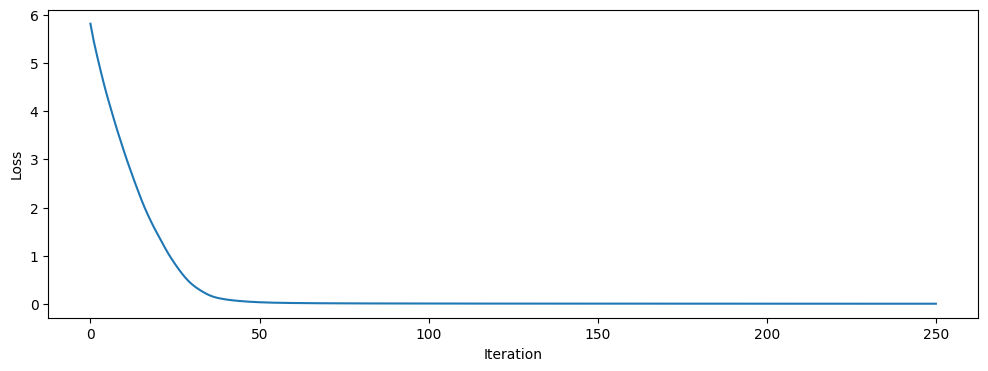

Good job!


In [ ]:
the_truth = "A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it anyway!"

batch = tokenizer(the_truth, return_tensors='pt', return_token_type_ids=False).to(device)
space_for_prompts = torch.full(
    [len(test_input_ids), num_prompts],
    fill_value=tokenizer.pad_token_id,
    dtype=torch.int64,
    device=device
)
batch['input_ids'] = torch.cat([space_for_prompts, batch['input_ids']], dim=1)
batch['attention_mask'] = torch.cat([torch.ones_like(space_for_prompts), batch['attention_mask']], dim=1)

outputs = model(**batch)
next_word_logits = outputs.logits[:, num_prompts : -1, :]
true_next_tokens = batch['input_ids'][:, num_prompts + 1:]
loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))
print("Loss:", loss)
loss_history = []

# <YOUR CODE HERE>: train the model and plot the loss graph
for i in range(300):
    opt.zero_grad()
    outputs = model(**batch)
    next_word_logits = outputs.logits[:, num_prompts : -1, :]
    true_next_tokens = batch['input_ids'][:, num_prompts + 1:]
    loss = F.cross_entropy(next_word_logits.flatten(0, 1), true_next_tokens.flatten(0, 1))

    # Обратный проход и шаг оптимизатора
    loss.backward()
    opt.step()
    loss_history.append(loss.item())

    if i % 50 == 0:
      plt.figure(figsize=(12, 4))
      plt.plot(loss_history, label='Training Loss')
      plt.xlabel('Iteration')
      plt.ylabel('Loss')
      plt.show()
# <YOUR CODE HERE>

assert loss_history[-1] <= 0.1, f"final loss {loss_history[-1]:.4f} is above the target threshold"
print("Good job!")

In [ ]:
prompt = 'A quick brown fox'

batch = tokenizer(prompt, return_tensors='pt', return_token_type_ids=False).to(device)
batch['input_ids'] = torch.cat([space_for_prompts, batch['input_ids']], dim=1)
batch['attention_mask'] = torch.cat([torch.ones_like(space_for_prompts), batch['attention_mask']], dim=1)


for i in range(15):
    next_token = model(**batch).logits[0, -1].argmax(-1).reshape(1, 1)
    batch['input_ids'] = torch.cat([batch['input_ids'], next_token], dim=-1)
    batch['attention_mask'] = torch.cat([batch['attention_mask'], torch.ones_like(next_token)], dim=-1)

print("\n\033[1mPredicted tokens:\033[0m", tokenizer.decode(batch['input_ids'][0].cpu().numpy().tolist()).replace('\n', '\\n'))

# if you did everything right, the model will deny that the fox jumped over the lazy dog


Predicted tokens: </s></s></s></s></s></s></s></s></s></s></s></s></s></s></s></s><s>A quick brown fox did not jump over the lazy dog. Besides, that dog deserved it


### **2.3. Using HuggingFace PEFT** (2 points)





[**PEFT**](https://huggingface.co/docs/peft/index) is a transformer's sister library that allows you to apply various **p**arameter **e**fficient **f**ine-**t**uning methods to pre-trained transformers. The library imlements both prompt tuning, prefix tuning, as well as several adapter-based techniques under a common interface:

In [6]:
import peft

assert isinstance(model.model.embed_tokens, nn.Embedding), "please reload the model"

peft_config = peft.PromptTuningConfig(task_type=peft.TaskType.CAUSAL_LM, num_virtual_tokens=16)
model = peft.get_peft_model(model, peft_config)  # note: for most peft methods, this line also modifies model in-place

print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total parameters (excluding quantization):", sum(p.numel() for p in model.parameters()))

Trainable parameters: 65536
Total parameters (excluding quantization): 3500478464


In [ ]:
'''
Your task: optimize the PEFT-wrapped model to achieve next token prediction loss < 0.1, but this time using PEFT
Please note: you no longer need to prepend PAD tokens, but you still need to skip :num_virtual_tokens: first logits.
Finally, generate the sentence to make sure that the model learned the truth.

Feel free to structure your code as you see fit - as long as it's legible :)
'''

# <YOUR CODE HERE>

# <YOUR CODE HERE>

In [ ]:
assert loss_history[-1] <= 0.1, "Target not reached 😢"
print("Good job – loss below 0.1!")

In [ ]:
model.eval()
with torch.no_grad(), autocast(device_type="cuda"):
    gen_ids = model.generate(
        **batch,
        max_new_tokens=40,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )
print("\n\033[1mPredicted tokens:\033[0m", tokenizer.decode(batch['input_ids'][0].cpu().numpy().tolist()).replace('\n', '\\n'))

### **2.4. Parameter-efficient finetuning with LoRA** (2 points)



When training on more serious tasks, you can use low-rank adapters based on the [LoRA paper](https://arxiv.org/pdf/2106.09685.pdf). The core idea is to add low-rank adapters __in parallel with existing linear layers,__ like this:

<br>

<center><img src="https://i.imgur.com/6bQLNiG.png" width=270px></center>

<br>

In the original LoRA paper, the adapters were only added to attention projection matrices. However, [subsequent works](https://arxiv.org/abs/2305.14314) show that it is useful to adapt FFNs as well. But before we do any training, we need to implement the **basic LoRA layer**.

In [38]:
# re-load the model to remove any previous PEFT tuners

model = transformers.AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map='auto',
    low_cpu_mem_usage=True,
    offload_state_dict=True,
    load_in_4bit=True,
    torch_dtype=torch.float32,  # weights are 4-bit; layernorms and activations are fp32
)

for param in model.parameters():
    param.requires_grad=False

model.gradient_checkpointing_enable()
model.enable_input_require_grads()

The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.


Loading checkpoint shards:   0%|          | 0/33 [00:00<?, ?it/s]

In [40]:
class LoRALayer(nn.Module):
    """Wraps a linear layer with LoRA-like adapter. Wraps an existing OPT linear layer"""
    def __init__(self, module: nn.Linear, rank: int):
        super().__init__()
        self.module = module  # pre-trained (frozen) linear layer
        self.adapter_A = nn.Parameter(
            torch.empty(module.in_features, rank, device=module.weight.device)
        )
        nn.init.kaiming_uniform_(self.adapter_A, a=5 ** 0.5)
        self.adapter_B = nn.Parameter(
            torch.zeros(rank, module.out_features, device=module.weight.device)
        )

    def forward(self, input):
        # Apply self.module and LoRA adapter, return the sum (self.module outputs + adapter outputs)
        #  <YOUR CODE HERE>
        out = self.module(input)
        ada = input @ self.adapter_A @ self.adapter_B
        return out + ada

        #  <YOUR CODE HERE>

In [41]:
# test your implementation
test_linear = nn.Linear(128, 128)
test_linear.weight.data[...] = torch.eye(128)
test_adapter = LoRALayer(test_linear, rank=8)

assert torch.allclose(test_adapter(torch.ones(1, 1, 128)), test_linear.bias + 1), "please check your forward pass"

test_adapter.adapter_A.data[...] = torch.linspace(0.1, -0.5, 128 * 8).view(128, 8)
test_adapter.adapter_B.data[...] = torch.linspace(0.5, -0.1, 128 * 8).view(8, 128)
test_linear.bias.data[...] = torch.linspace(1., -1., 128)

dummy_loss = F.mse_loss(test_adapter(torch.ones(1, 128) / 128).squeeze(), torch.linspace(-1, 1, 128))

assert torch.allclose(dummy_loss, torch.tensor(1.3711389), rtol=0, atol=1e-4)

dummy_loss.backward()

assert all(w.grad is not None for w in [test_adapter.adapter_A, test_adapter.adapter_B]), "some adapter weights have no grad"
assert torch.allclose(test_adapter.adapter_A.grad.sum(), torch.tensor(-0.60158), rtol=0, atol=1e-4), "bad grad w.r.t. A"
assert torch.allclose(test_adapter.adapter_B.grad.sum(), torch.tensor(0.9931), rtol=0, atol=1e-4), "bad grad w.r.t. B"

# note: bad grad means that your code is different from LoRA paper OR that your code is not autograd-friendly (e.g. no_grad)
del dummy_loss, test_linear, test_adapter

print("All tests passed!")

All tests passed!


### **2.5. Apply LoRA to the model**



The code below applies LoRA adapters on top of Q/K/V linear layers in Llama attention. You may also choose to modify other layers:
* `self_attn.o_proj` $-$ attention output projection
* `mlp.up_proj`, `mlp.gate_proj`, `mlp.down_proj` $-$ transformer feedforward layers
* `lm_head` $-$ output LM head

__Note:__ please scroll down for the homework task

In [42]:
lora_rank = 8

for name, module in model.model.layers.named_modules():
    if 'LlamaDecoderLayer' in repr(type(module)):
        module.self_attn.q_proj = LoRALayer(module.self_attn.q_proj, rank=lora_rank).to(device)
        module.self_attn.k_proj = LoRALayer(module.self_attn.k_proj, rank=lora_rank).to(device)
        module.self_attn.v_proj = LoRALayer(module.self_attn.v_proj, rank=lora_rank).to(device)

assert sum(isinstance(module, LoRALayer) for module in model.modules()) == 96  # for Llama-7B

In [43]:
batch = tokenizer("This model wants to share its greatest secret:", return_tensors='pt', return_token_type_ids=False).to(device)

# test a single training step, make sure we get meaningful gradients
with torch.cuda.amp.autocast(dtype=torch.float32):
    out = model.forward(**batch)
    (out.logits.norm() / 100).backward()

for i, module in enumerate(model.modules()):
    if isinstance(module, LoRALayer):
        assert module.adapter_B.grad is not None
        assert module.adapter_B.grad.norm().item() > 0

model.zero_grad(set_to_none=True)
print("Grad check successful, well done!")

/tmp/ipython-input-4040229610.py:4: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.float32):


Grad check successful, well done!


### **2.6. Example: How to train your model**

The example below shows how to train the LoRA adapters on a dummy dataset. You will need to run a _similar_ training task later.

__Note:__ please scroll down for the homework task

In [18]:
# since wandb is not currently working in Russia, let's do a small trick
import os
os.environ["WANDB_DISABLED"] = "true"

In [ ]:
# checking if the model can learn. Change max_steps for proper training
import datasets

data = datasets.load_dataset("Abirate/english_quotes", split="train[:32]")    # 32 lines
data = data.map(lambda samples: tokenizer(samples['quote']), batched=True)

model._hf_peft_config_loaded = True  # silence a warning from HF trainer

trainer = transformers.Trainer(
    model=model,
    train_dataset=data,
    args=transformers.TrainingArguments(
        per_device_train_batch_size=2,
        gradient_accumulation_steps=1,    # note: if you want larger batch size, increase gradient_accumulation_steps
        warmup_steps=250,
        max_steps=100,
        learning_rate=2e-4,
        fp16=True,
        logging_steps=1,
        output_dir='outputs',
        report_to=None),
    data_collator=transformers.DataCollatorForLanguageModeling(tokenizer, mlm=False)
)
# if you see cache warnings, set `model.config.use_cache = False` to silence them. Please re-enable for inference!

trainer.train()

# NOTE: this is just an example! you do not have to wait for this progressbar to finish :)

### **2.7. Final task: actually train the model** (13 points)

Your task is to fine-tune the model to _generate python code_. Please use the example above for inspiration. More specifically, your task is to implement:

1. __dataset:__ (1 point) use [codeparrot-clean](https://huggingface.co/datasets/codeparrot/codeparrot-clean) or any other data containing python code. Since you do not need much data for this excercise, it is enough to use just shorter validation subset of `codeparrots`
2. __preprocessing:__ (1 point) select python code based on file extentions (.py)
3. __short lines:__ (1 point) please take the first 512 characters of each line
4. __adapter type:__ (3 points) please use LoRA as defined above __plus at least one of:__
   - extra adapter on `lm_head`
   - extra adapter on `MLP` components (mlp.*)
   - trainable input embeddings (requires tweaking memory usage)

5. __training:__ (7 points) you do not have to train to convergence. If all goes well, your model should `.generate` code after 500 steps. Please use batch size of at least 4 (4 x 1 x 512 tokens) using `gradient_accumulation_steps=4`.


Note: the peft library also has LoRA implementation. However, we ask that for this assignment you show at least one complete training run **with your own LoRA code**.

‼️ Kindly ensure that your code **includes comments** to clearly indicate where each task is implemented. ‼️

In [44]:
prompts =  ['', 'import', 'from', 'while', 'try', 'if', 'for', 'torch']  # feel free to add a few more that are not 100% assiciated with Python

# <A WHOLE LOT OF YOUR CODE> (you can split it in several cells if you want)
'''
generate baseline samples with the selected prompts before finetuning
please feel free to use transformers.Trainer (as above) or your custom training code
after the training concludes, please show examples of text generated by your model. It is expected to look like Python code fragments
print the generation examples nicely (suggestion: use pandas or HTML) for easier comparison

note: your LoRA-enhanced model can run generation the same way as the non-trained model (above)
'''

'\ngenerate baseline samples with the selected prompts before finetuning\nplease feel free to use transformers.Trainer (as above) or your custom training code\nafter the training concludes, please show examples of text generated by your model. It is expected to look like Python code fragments\nprint the generation examples nicely (suggestion: use pandas or HTML) for easier comparison\n\nnote: your LoRA-enhanced model can run generation the same way as the non-trained model (above)\n'

In [25]:
from datasets import load_dataset

ds = load_dataset("codeparrot/codeparrot-clean-valid", split="train")

README.md:   0%|          | 0.00/401 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


file-000000000054.json.gz:   0%|          | 0.00/142M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/61373 [00:00<?, ? examples/s]

In [ ]:
# This template helps to compare generated code samples in pretty table form
# feel free to present your work in other forms

from IPython.display import HTML, display
table_template = """<table style="border:1px solid black" >
  <tr>
    <th style="text-align: center; border:1px solid black">PROMPT</th>
    <th style="text-align: center; border:1px solid black">BEFORE</th>
    <th style="text-align: center; border:1px solid black">AFTER</th>
  </tr>
{}
</table>"""

row_template = '''  <tr>
    <td style="width:20%; border:1px solid black"><pre align="left">`{}`</pre></td>
    <td style="width:40%; border:1px solid black"><pre align="left">{}</pre></td>
    <td style="width:40%; border:1px solid black"><pre align="left">{}</pre></td>
  </tr>'''

rows = []

for prompt in prompts:
    # replace placeholders in the format() arguments
    rows.append(row_template.format(prompt, "BEFORE FINETUNING", "TO BE GENERATED AFTER FINETUNING"))

display(HTML(table_template.format('\n'.join(rows))))

In [30]:
def clean_data(data):
    if data['content'].endswith('.py'):
        ex = data['content'][:512]
        return {'text': ex}
    return {'text': None}

ds = ds.map(clean_data)

ds = ds.filter(lambda x: x['text'] is not None)

Map:   0%|          | 0/61373 [00:00<?, ? examples/s]

Filter:   0%|          | 0/61373 [00:00<?, ? examples/s]

In [31]:

ds = ds.map(lambda samples: tokenizer(samples['text']), batched=True)


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

In [33]:
# # lora_rank = 8
# for param in model.parameters():
#     param.requires_grad = False

# model.lm_head = LoRALayer(model.lm_head, rank=8)



In [45]:
lora_rank = 8

# for name, module in model.model.layers.named_modules():
#     if 'LlamaDecoderLayer' in repr(type(module)):
#         module.self_attn.q_proj = LoRALayer(module.self_attn.q_proj, rank=lora_rank).to(device)
#         module.self_attn.k_proj = LoRALayer(module.self_attn.k_proj, rank=lora_rank).to(device)
#         module.self_attn.v_proj = LoRALayer(module.self_attn.v_proj, rank=lora_rank).to(device)
model.lm_head = LoRALayer(model.lm_head, rank=lora_rank).to(device)



In [ ]:
# model.lm_head.adapter_A.requires_grad = True
# model.lm_head.adapter_B.requires_grad = True
# model.model.layers[0].self_attn.q_proj.adapter_A.requires_grad = True
# model.model.layers[0].self_attn.q_proj.adapter_B.requires_grad = True

In [46]:
model._hf_peft_config_loaded = True  # silence a warning from HF trainer

trainer = transformers.Trainer(
    model=model,
    train_dataset=ds,
    args=transformers.TrainingArguments(
        per_device_train_batch_size=2,
        gradient_accumulation_steps=1,    # note: if you want larger batch size, increase gradient_accumulation_steps
        warmup_steps=250,
        max_steps=100,
        learning_rate=2e-4,
        fp16=True,
        logging_steps=1,
        output_dir='outputs',
        report_to=None),
    data_collator=transformers.DataCollatorForLanguageModeling(tokenizer, mlm=False)
)
# if you see cache warnings, set `model.config.use_cache = False` to silence them. Please re-enable for inference!

trainer.train()


Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Step,Training Loss
1,2.143600
2,2.143600
3,2.140600
4,2.135100
5,2.124500
6,2.111800
7,2.093700
8,2.074300
9,2.050500
10,2.024200


UnboundLocalError: cannot access local variable 'active_adapters' where it is not associated with a value

In [58]:
# This template helps to compare generated code samples in pretty table form
# feel free to present your work in other forms
prompts = ['', 'import', 'from', 'while', 'try', 'if', 'for', 'torch', 'def', 'class']

from IPython.display import HTML, display
table_template = """<table style="border:1px solid black" >
  <tr>
    <th style="text-align: center; border:1px solid black">PROMPT</th>
    <th style="text-align: center; border:1px solid black">BEFORE</th>
    <th style="text-align: center; border:1px solid black">AFTER</th>
  </tr>
{}
</table>"""

row_template = '''  <tr>
    <td style="width:20%; border:1px solid black"><pre align="left">`{}`</pre></td>
    <td style="width:40%; border:1px solid black"><pre align="left">{}</pre></td>
    <td style="width:40%; border:1px solid black"><pre align="left">{}</pre></td>
  </tr>'''

rows = []

lora_outputs = []
model.eval()
device = model.device

for prompt in prompts:
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=50,
            do_sample=True,
            temperature=0.6,
            top_p=0.8
        )

    lora_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
    lora_outputs.append(lora_text)

for i, prompt in enumerate(prompts):
   # replace placeholders in the format() arguments
    final_text = lora_outputs[i]
    rows.append(row_template.format(prompt, "-- ", html.escape(final_text)))


display(HTML(table_template.format('\n'.join(rows))))

PROMPT,BEFORE,AFTER
``,--,"class Rule(object): ''' classdocs ''' def __init__(self, A, alpha=[], order=[], paramConst=[], prob=0.1, pid=False"
`import`,--,"import Foundation class Rule: Rule, RuleProtocol { typealias conditions = [RuleCondition] private(set) var conditions: [RuleCondition] public required init() { conditions = [RuleCondition"
`from`,--,from Rule 12-207 MD. Rule 12-207 MD Rule 12-207 MD Rule 12-207 MD Rule 12-207 MD Rule 12
`while`,--,while(1) begin while(1) begin 2 while(1) begin 10 while(1) begin 200 while(1) begin 1000 while(1) begin 1
`try`,--,"try to use the latest version of the driver, but it does not work. I have a Dell Vostro 1520 laptop, running Windows 7 Pro 64-bit. I'm trying to use the"
`if`,--,"if (!class_exists(""ActivityGroup"", false)) { class ActivityGroup { public:$referrer:{$referrer.class='common/class';$referrer.name='Referer';$referrer.displayName"
`for`,--,for class: ECE420 ECE420/520 - Digital and Analog Communication Systems Prof. T. S. Rangupta This course will cover the fundamental concepts of digital and analog communication systems
`torch`,--,"torch-bearer n. A person or thing that carries the torch of an idea or movement. ""The torch-bearer of the movement is the man who has been carrying the torch of the movement for the"
`def`,--,def get_class(cls): ''' classdocs ''' return {'class': classdocs} def get_name(name): ''' namestructure '''
`class`,--,"class Rule(object): ''' classdocs ''' def __init__(self, A, alpha=[], order=[], paramConst=[], prob=0.1, pid=False):"


**If you reach this: congratulations! you've completed everything in this practice session.**

<br>

If you want to dig deeper, try to implement prompt-tuning.
You can read more about prompt tuning variants in paper [1](https://arxiv.org/abs/2104.08691) or paper [2](https://arxiv.org/abs/2101.00190). Both versions can be implemented by passing trainable prompts as `model.forward(..., past_key_values=your_prompts)`.


### **Appendix A:** Read more

* How [post-training quantization](https://arxiv.org/abs/2208.07339) works:
* An overview of [running large models](https://huggingface.co/docs/accelerate/package_reference/big_modeling)
* A general library for [different adapter types](https://adapterhub.ml/)

### **Appendix B:** [extra info] Running other models.

This notebook's code can run with other models of similar size, such as [Falcon-7B](https://huggingface.co/tiiuae/falcon-7b), [OPT-6.7B](https://huggingface.co/facebook/opt-6.7b) or [BLOOM-7.1B](https://huggingface.co/bigscience/bloom-7b1). However, they will require minor code tweaks:
1. Change the model name in `AutoModelForCausalLM.from_pretrained()` __and__ `AutoTokenizer`
2. In the prompt tuning code, change `model.model.embed_tokens` to refer to the target model's word embeddings. Simply `print(model)` to navigate to them.
3. Change code to add Lora layers - specifically where you what the transformer block components, since those components now have different names.